# NFNet — Normalizer-Free Networks

**Paper**: Brock, A., De, S., Smith, S. L., & Simonyan, K. (2021).  
**"High-Performance Large-Scale Image Recognition Without Normalization"**  
ICML 2021 · arXiv:2102.06171  
DeepMind

---

## Why This Paper Matters

BatchNorm is everywhere in deep learning — it stabilises training and acts as implicit regularisation. But it has well-known pathologies:
- **Train/eval discrepancy**: BN uses batch statistics at train time but running averages at eval.
- **Small-batch instability**: batch statistics become noisy with batch size < 16.
- **Incompatibility with some architectures**: recurrent nets, certain distributed training setups.

NFNet proved none of this is necessary. NFNet-F5 reached **89.2% top-1 on ImageNet** — matching the best EfficientNets — with **zero BatchNorm layers**.  

The key: replace BN with **Scaled Weight Standardisation** and fix the residual variance explosion with a careful scaling scheme.

> 📄 **Paper:** Brock, De, Smith & Simonyan (2021). High-Performance Large-Scale Image Recognition Without Normalization. ICML 2021.
> 🔗 **Link:** <https://arxiv.org/abs/2102.06171>
> 🧩 **Implementation:** `hale_core/nn/vision/cnn/nfnet.py` (reproduced in full in §4 - runs with plain PyTorch)

**How this notebook is organised:** 1. paper & idea · 2. architecture diagrams (Mermaid, ASCII, matplotlib) ·
3. key ideas · 4. the full architecture in pure PyTorch · 5. build & run · 6. parameters vs paper & gradient flow ·
7. equivalence with the library · 8. feature maps · references.

## 2. Architecture diagram

Colours: <span style="color:#d48806">■ input</span> · <span style="color:#1f77b4">■ stages</span> ·
<span style="color:#8e44ad">■ blocks / operations</span> · <span style="color:#c0392b">■ outputs</span>.
(Mermaid renders on GitHub, in JupyterLab ≥ 4.1 and VS Code; an ASCII and a matplotlib version follow.)

```mermaid
flowchart TB
  IN["image (B, 3, 192, 192)"]:::io --> STEM["4 × WSConv 3×3 (stem) /4"]:::stage
  STEM --> S["NF stages ×[1,2,6,3] (F0), widths 256·512·1536·1536"]:::stage --> HEAD["1×1 WSConv → 2×C · GELU"]:::block --> GAP["avg pool"]:::block --> OUT
  subgraph NFB["NF-ResNet block (no BatchNorm)"]
    direction LR
    X["x"] --> PRE["GELU(x) · β⁻¹ (expected std)"]:::block --> CONVS["WSConv 1×1 → grouped 3×3 ×2 → 1×1"]:::block --> SE["SE · 2"]:::block --> SK["× skip-gain (init 0) · α"]:::block --> ADD(("+"))
    X --> ADD
  end
  S -.-> NFB
  AGC["Adaptive Gradient Clipping (training)"]:::block -.-> NFB
  OUT["BackboneOutput<br/>pooled_output (B, embed_dim)<br/>feature_maps finest → coarsest<br/>patch_tokens = None"]:::out
  classDef io fill:#fff7e6,stroke:#d48806,color:#222
  classDef stage fill:#eaf2fb,stroke:#1f77b4,color:#222
  classDef block fill:#f1e6f8,stroke:#8e44ad,color:#222
  classDef out fill:#fdecea,stroke:#c0392b,color:#222
```

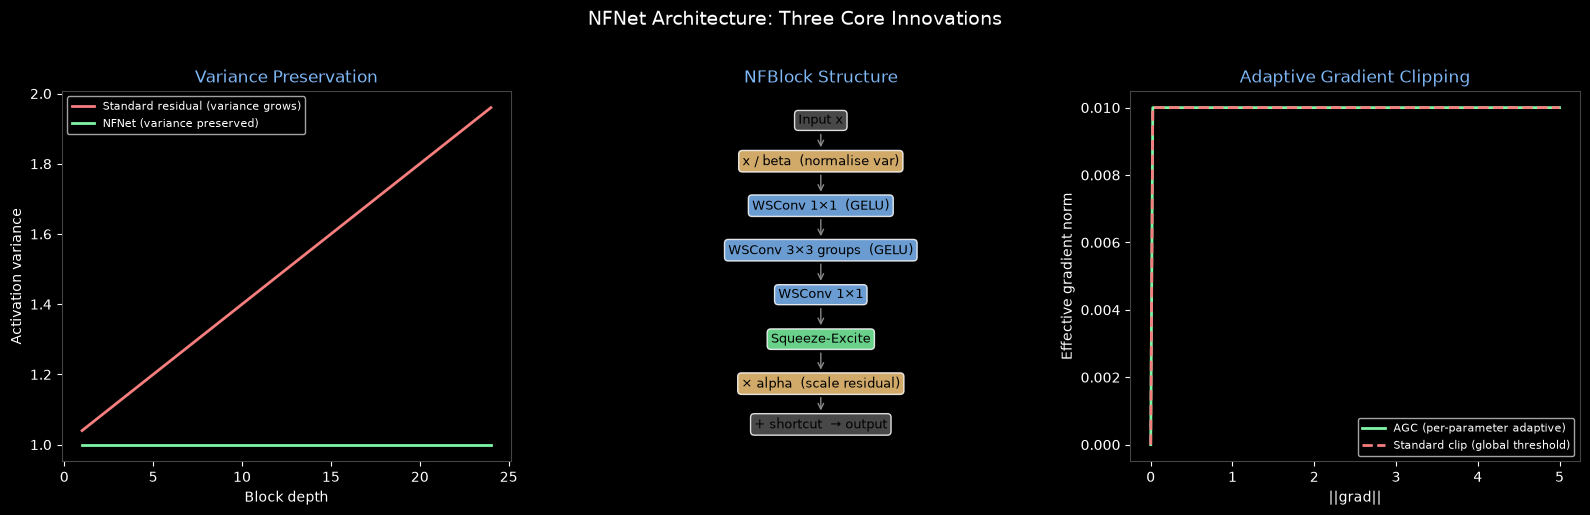

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.style.use('dark_background')
ACCENT = '#7EB8F7'
RED    = '#F77E7E'
GREEN  = '#7EF7A4'
GOLD   = '#F7C97E'

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('NFNet Architecture: Three Core Innovations', fontsize=14, color='white', y=1.02)

# --- Panel 1: Variance growth with/without NFNet fix ---
ax = axes[0]
blocks = np.arange(1, 25)
# Standard residual: Var(y_k) = k * Var(residual_branch) + Var(x_0)
var_std  = 1.0 + 0.04 * blocks  # grows linearly
var_nfnet = np.ones_like(blocks, dtype=float)  # stays near 1
ax.plot(blocks, var_std,   color=RED,   lw=2, label='Standard residual (variance grows)')
ax.plot(blocks, var_nfnet, color=GREEN, lw=2, label='NFNet (variance preserved)')
ax.set_xlabel('Block depth', color='white')
ax.set_ylabel('Activation variance', color='white')
ax.set_title('Variance Preservation', color=ACCENT)
ax.legend(fontsize=8)
ax.tick_params(colors='white')
for spine in ax.spines.values(): spine.set_color('#444')

# --- Panel 2: NFBlock structure (visual flow) ---
ax = axes[1]
ax.set_xlim(0, 4)
ax.set_ylim(0, 10)
ax.axis('off')
ax.set_title('NFBlock Structure', color=ACCENT)

steps = [
    (2, 9.2, 'Input x', '#555'),
    (2, 8.1, 'x / beta  (normalise var)', GOLD),
    (2, 6.9, 'WSConv 1×1  (GELU)', ACCENT),
    (2, 5.7, 'WSConv 3×3 groups  (GELU)', ACCENT),
    (2, 4.5, 'WSConv 1×1', ACCENT),
    (2, 3.3, 'Squeeze-Excite', GREEN),
    (2, 2.1, '× alpha  (scale residual)', GOLD),
    (2, 1.0, '+ shortcut  → output', '#555'),
]
for x, y, label, col in steps:
    ax.text(x, y, label, ha='center', va='center', fontsize=9,
            color='black', bbox=dict(boxstyle='round,pad=0.3', facecolor=col, alpha=0.85))

# Draw arrows
ys = [s[1] for s in steps]
for y0, y1 in zip(ys[:-1], ys[1:]):
    ax.annotate('', xy=(2, y1 + 0.3), xytext=(2, y0 - 0.3),
                arrowprops=dict(arrowstyle='->', color='#888'))

# --- Panel 3: Adaptive Gradient Clipping vs standard ---
ax = axes[2]
grad_norms = np.linspace(0, 5, 200)
param_norm = 1.0
lambda_    = 0.01
# AGC: clip to lambda * ||w|| / ||g|| * ||g|| = lambda * ||w||
agc_clip   = np.minimum(grad_norms, param_norm * lambda_)
# Standard global clip at threshold=0.01
std_clip   = np.minimum(grad_norms, 0.01)
ax.plot(grad_norms, agc_clip, color=GREEN, lw=2, label='AGC (per-parameter adaptive)')
ax.plot(grad_norms, std_clip, color=RED,   lw=2, linestyle='--', label='Standard clip (global threshold)')
ax.set_xlabel('||grad||', color='white')
ax.set_ylabel('Effective gradient norm', color='white')
ax.set_title('Adaptive Gradient Clipping', color=ACCENT)
ax.legend(fontsize=8)
ax.tick_params(colors='white')
for spine in ax.spines.values(): spine.set_color('#444')

plt.tight_layout()
plt.show()

## 3. Key ideas

## Mathematical Formulation

### 1. Scaled Weight Standardisation (SWS)

For a convolutional weight tensor $W \in \mathbb{R}^{C_{out} \times C_{in} \times k \times k}$:

$$\hat{W}_i = \frac{W_i - \mu_i}{\sigma_i + \epsilon} \cdot \frac{\gamma_i}{\sqrt{\text{fan\_in}}}$$

where $\mu_i = \mathbb{E}[W_i]$, $\sigma_i = \text{Std}(W_i)$ over the $C_{in} \times k \times k$ dims, and $\gamma_i$ is a learnable per-output-channel gain parameter.  
This ensures that each filter's convolution output has approximately **unit variance** under a normalised input.

### 2. Variance Preservation in Residual Blocks

Standard residuals accumulate variance: $\text{Var}(y_k) = k\,\text{Var}(F) + \text{Var}(x_0)$ (grows with depth).

NFNet corrects this with:
$$y_k = x_k + \alpha \cdot F\!\left(\frac{x_k}{\beta_k}\right)$$

where $\beta_k = \sqrt{\text{Var}(x_k)} \approx \sqrt{1 + \alpha^2(k-1)}$ (accumulated std), and $\alpha \approx 0.2$ (learnable scalar).  
The normalised input $x_k/\beta_k$ has unit variance; the $\alpha$ scale ensures $\text{Var}(y_k) \approx \text{Var}(x_k)$.

### 3. Adaptive Gradient Clipping (AGC)

For each parameter $\theta$:
$$g^* = g \cdot \min\!\left(1,\;\frac{\lambda \,\|\theta\|_F}{\|g\|_F}\right)$$

where $\|\cdot\|_F$ is the Frobenius norm computed **per-layer** (not globally), and $\lambda = 0.01$ is the clipping coefficient.  
This prevents any layer's gradient from exceeding a fraction $\lambda$ of its weight norm.

## 4. The architecture in pure PyTorch

Below is the **complete implementation** used by HaleBlocks (`hale_core/nn/vision/cnn/nfnet.py`), one top-level
definition per cell, with its original comments and docstrings. Only the `hale_core` imports were replaced by the
two foundation cells (the `BackboneOutput` / `BaseVisionBackbone` contract and a 10-line registry), so this notebook
runs anywhere PyTorch is installed. §7 checks it is bit-for-bit the library implementation.

<details><summary>Module docstring of <code>cnn/nfnet.py</code></summary>

```text
NFNet Vision Backbones
======================

Implements the Normalizer-Free Network family (Brock et al. 2021,
"High-Performance Large-Scale Image Recognition Without Normalization",
https://arxiv.org/abs/2102.06171).

Architecture
------------
NFNet achieves state-of-the-art accuracy without BatchNorm via three innovations:

  1. Scaled Weight Standardisation (SWS): normalises convolution weights at
     each forward pass so activation variance stays bounded, replacing BN.

  2. Variance Preservation in Residual Branches: the standard residual formula
     ``y = x + F(x)`` grows activation variance monotonically.  NFNet corrects
     this with ``y = x + alpha * F(x / beta)`` where alpha ≈ 0.2 (learned) and
     beta = sqrt(accumulated variance), keeping Var(y) ≈ Var(x).

  3. Adaptive Gradient Clipping (AGC): clips gradients by the ratio of the
     parameter norm to the gradient norm, ``g ← g * min(1, λ ||w|| / ||g||)``.
     This is a training-time utility; see ``agc_clip()`` below.

Block structure
---------------
  NFBlock (SE variant, group conv):
    WSConv 1×1 (pre-activation, /beta)
    → GELU
    → WSConv 3×3 groups=group_size (stride if downsample)
    → GELU
    → WSConv 1×1
    → SE (squeeze-excite, squeeze_ratio=0.5)
    → * alpha (learnable)
    → + residual (projected shortcut if needed)

Stage configs (widths, depths, group_size=128):
  F0: depths=[1,2,6,3],   widths=[256,512,1536,1536]
  F1: depths=[2,4,12,6],  widths=[256,512,1536,1536]
  F2: depths=[3,6,18,9],  widths=[256,512,1536,1536]
  F3: depths=[4,8,24,12], widths=[256,512,1536,1536]
  F4: depths=[5,10,30,15],widths=[256,512,1536,1536]
  F5: depths=[6,12,36,18],widths=[256,512,1536,1536]

Stem: 4 WSConv2d layers totalling 4× spatial reduction.

Registered names
----------------
  nfnet_f0 — depths=[1,2,6,3]
  nfnet_f1 — depths=[2,4,12,6]
  nfnet_f2 — depths=[3,6,18,9]
  nfnet_f3 — depths=[4,8,24,12]
  nfnet_f4 — depths=[5,10,30,15]
  nfnet_f5 — depths=[6,12,36,18]

Citation
--------
  Brock, A., De, S., Smith, S. L., & Simonyan, K. (2021).
  High-Performance Large-Scale Image Recognition Without Normalization. ICML.
  arXiv:2102.06171
```
</details>

In [2]:
from __future__ import annotations

# Everything below is plain PyTorch - no hale_core import is needed to run this notebook.
import math
from abc import ABC, abstractmethod
from copy import deepcopy
from dataclasses import dataclass, field
from typing import Any, Callable, Optional, Type, TypeVar, Union

import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(min(4, torch.get_num_threads()))
print("torch", torch.__version__)

torch 2.14.1


### 4.1 Foundation: the backbone contract (`base.py`) and a local registry

In [3]:
@dataclass
class BackboneOutput:
    """Standard output container for all vision backbones.

    Attributes
    ----------
    pooled_output:
        Global image representation after spatial pooling. Shape [B, embed_dim].
        Used by: classification heads, VLM projectors, action encoders.

    patch_tokens:
        Per-patch (or per-pixel) feature tokens BEFORE pooling.
        Shape [B, N, embed_dim] for ViT-style; None for pure CNNs.
        Used by: VLM cross-attention, dense grounding.

    feature_maps:
        Multi-scale spatial feature tensors, ordered finest → coarsest.
        Each element: [B, C_i, H/s_i, W/s_i] where s_i is the stride.
        Used by: FPN, BEV encoder, depth heads.

    attentions:
        Optional list of attention weight tensors from each transformer block.
        Used for interpretability (attention rollout, DINO self-supervised heads).
    """

    pooled_output: torch.Tensor                          # [B, embed_dim]
    patch_tokens:  Optional[torch.Tensor] = None        # [B, N, D] or None
    feature_maps:  list[torch.Tensor] = field(default_factory=list)  # multi-scale
    attentions:    Optional[list[torch.Tensor]] = None  # transformer attention maps


class BaseVisionBackbone(ABC, nn.Module):
    """Abstract base for all vision backbones.

    Subclasses MUST define:
      - arch_name  (str): human-readable identifier, e.g. "resnet50"
      - embed_dim  (int): dimension of pooled_output
      - feature_dims (list[int]): channel counts for each feature map scale
      - forward(x) -> BackboneOutput

    Args:
        img_size:   Expected input spatial resolution (height == width assumed).
        in_chans:   Number of input image channels (default 3 for RGB).
        drop_rate:  Dropout probability applied to the final pooled features.
        out_indices: Which multi-scale feature stages to include in BackboneOutput.
                     E.g. [0, 1, 2, 3] returns all four scales; [2, 3] returns
                     only the two coarsest.  Default returns all available.
    """

    # ── Class-level metadata — override in each subclass ─────────────────────
    arch_name:    str        = "base"
    embed_dim:    int        = 0
    feature_dims: list[int] = []   # channel counts per stage, finest→coarsest

    def __init__(
        self,
        img_size:    int        = 224,
        in_chans:    int        = 3,
        drop_rate:   float      = 0.0,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__()
        self.img_size    = img_size
        self.in_chans    = in_chans
        self.drop_rate   = drop_rate
        self.out_indices = out_indices  # None = return all stages

    @abstractmethod
    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """Run the backbone on a batch of images.

        Args:
            x: Float32 tensor of shape [B, in_chans, H, W].
               Typically ImageNet-normalised (mean=[0.485,0.456,0.406],
               std=[0.229,0.224,0.225]).

        Returns:
            BackboneOutput with pooled_output, patch_tokens, feature_maps.
        """
        ...

    # ── Convenience helpers ───────────────────────────────────────────────────

    def num_parameters(self, trainable_only: bool = False) -> int:
        """Count model parameters.

        Args:
            trainable_only: If True, count only parameters with requires_grad=True.

        Returns:
            Integer parameter count.
        """
        params = self.parameters()
        if trainable_only:
            params = (p for p in params if p.requires_grad)
        return sum(p.numel() for p in params)

    def freeze_all(self) -> None:
        """Freeze all parameters (no gradient computation).

        Useful when using the backbone as a frozen feature extractor
        inside a VLM or action decoder that only trains the head.
        """
        for p in self.parameters():
            p.requires_grad_(False)

    def unfreeze_all(self) -> None:
        """Unfreeze all parameters."""
        for p in self.parameters():
            p.requires_grad_(True)

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze all stages from 0 up to and including `stage`.

        Useful for fine-tuning: freeze the early feature extractor stages
        and only fine-tune the later stages.  The exact meaning of "stage"
        is backbone-specific; see each subclass's docstring.

        Args:
            stage: Stage index (0-based).  Stages 0..stage are frozen.
        """
        raise NotImplementedError(
            f"{self.__class__.__name__} does not implement freeze_up_to_stage()"
        )

    def __repr__(self) -> str:
        return (
            f"{self.__class__.__name__}("
            f"arch={self.arch_name}, "
            f"embed_dim={self.embed_dim}, "
            f"img_size={self.img_size}, "
            f"params={self.num_parameters():,})"
        )

In [4]:
# A minimal stand-in for hale_core.nn.vision.registry: same decorator name and behaviour, so the
# library source below runs unchanged. Re-registration is allowed so cells can be re-run.
_VISION_BACKBONES: dict[str, type] = {}
T = TypeVar("T")


def register_vision_backbone(name: str) -> Callable[[T], T]:
    """Class decorator: store ``cls`` under ``name`` (lower-case)."""
    def decorator(cls: T) -> T:
        _VISION_BACKBONES[name.lower()] = cls
        return cls
    return decorator


def build_vision_backbone(name: str, **kwargs: Any) -> "BaseVisionBackbone":
    """Instantiate a backbone registered in this notebook."""
    return _VISION_BACKBONES[name.lower()](**kwargs)


def list_vision_backbones() -> list[str]:
    return sorted(_VISION_BACKBONES)

### 4.2 `cnn/nfnet.py`, definition by definition

In [5]:
def agc_clip(model: nn.Module, lambda_: float = 0.01) -> None:
    """Adaptive Gradient Clipping: clips each parameter's gradient by its weight norm.

    Per-parameter clipping: g ← g * min(1, λ * ||w|| / ||g||).
    Should be called after loss.backward() before optimizer.step().

    Args:
        model:   The NFNet model (or any nn.Module with gradients).
        lambda_: Clipping coefficient (default 0.01, as in the paper).
    """
    for p in model.parameters():
        if p.grad is None:
            continue
        # Unit-wise norms (paper Sec. 4.1): one norm per output unit = per row of the weight,
        # i.e. over every dim except dim 0. Vectors (biases, gains) are clipped element-wise.
        # torch.linalg.vector_norm is required: Tensor.norm(dim=[1, 2, 3]) uses the Frobenius
        # *matrix* norm, which rejects more than two dims on recent PyTorch.
        dims = tuple(range(1, p.ndim))
        if dims:
            param_norm = torch.linalg.vector_norm(p.detach(), dim=dims, keepdim=True)
            grad_norm  = torch.linalg.vector_norm(p.grad, dim=dims, keepdim=True)
        else:
            param_norm, grad_norm = p.detach().abs(), p.grad.abs()
        param_norm = param_norm.clamp(min=1e-3)
        max_norm   = param_norm * lambda_
        clip_coef  = (max_norm / grad_norm.clamp(min=1e-6)).clamp(max=1.0)
        p.grad.mul_(clip_coef)

**`WSConv2d`** - Conv2d with Scaled Weight Standardisation (Brock et al. 2021, Sec. 3.1).

In [6]:
class WSConv2d(nn.Conv2d):
    """Conv2d with Scaled Weight Standardisation (Brock et al. 2021, Sec. 3.1).

    Normalises filter weights at forward time so that each conv output has
    approximately unit variance, eliminating the need for BatchNorm.

    A learnable per-output-channel gain ``self.gain`` scales the normalised
    weights to preserve the expected signal variance under GELU activations.
    """

    def __init__(self, *args, **kwargs) -> None:
        super().__init__(*args, **kwargs)
        # Per-output-channel gain (replaces BN's learnable scale)
        self.gain = nn.Parameter(torch.ones(self.out_channels, 1, 1, 1))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        w = self.weight
        # Subtract per-filter mean (dims: in_C, kH, kW)
        w = w - w.mean(dim=[1, 2, 3], keepdim=True)
        # Normalise variance — eps avoids div-by-zero for zero-weight filters
        w = w / (w.var(dim=[1, 2, 3], keepdim=True, unbiased=False) + 1e-5).sqrt()
        # Scale to maintain expected variance: gain / sqrt(fan_in)
        fan_in = w[0].numel()
        w = w * (self.gain / math.sqrt(fan_in))
        return F.conv2d(x, w, self.bias, self.stride, self.padding, self.dilation, self.groups)

**`SqueezeExcite`** - Channel attention: global-pool → squeeze linear → GELU → excite linear → sigmoid.

In [7]:
class SqueezeExcite(nn.Module):
    """Channel attention: global-pool → squeeze linear → GELU → excite linear → sigmoid."""

    def __init__(self, in_channels: int, squeeze_ratio: float = 0.5) -> None:
        super().__init__()
        mid = max(1, int(in_channels * squeeze_ratio))
        self.squeeze = nn.Linear(in_channels, mid)
        self.excite  = nn.Linear(mid, in_channels)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: [B, C, H, W]
        scale = x.mean(dim=[2, 3])           # [B, C] global average pool
        scale = F.gelu(self.squeeze(scale))  # [B, mid]
        scale = torch.sigmoid(self.excite(scale))  # [B, C]
        return x * scale.unsqueeze(-1).unsqueeze(-1)

**`StochasticDepth`** - Randomly drops the entire block output during training.

In [8]:
class StochasticDepth(nn.Module):
    """Randomly drops the entire block output during training."""

    def __init__(self, drop_prob: float) -> None:
        super().__init__()
        self.drop_prob = drop_prob

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if not self.training or self.drop_prob == 0.0:
            return x
        keep_prob = 1.0 - self.drop_prob
        shape = (x.shape[0],) + (1,) * (x.ndim - 1)
        noise = torch.floor(torch.rand(shape, dtype=x.dtype, device=x.device) + keep_prob)
        return x * noise / keep_prob

**`NFBlock`** - Normalizer-Free residual block with variance preservation.

In [9]:
class NFBlock(nn.Module):
    """Normalizer-Free residual block with variance preservation.

    Uses the formula: y = x + alpha * F(x / beta)
    where alpha (scalar, ≈0.2) scales the residual branch to prevent variance
    accumulation, and beta = expected_std_of_x normalises the input.

    Args:
        in_channels:   Input channel count.
        out_channels:  Output channel count.
        stride:        Spatial stride for the 3×3 conv.
        group_size:    Group width for grouped conv.
        beta:          Expected input standard deviation (accumulated across blocks).
        alpha:         Residual branch scale factor.
        squeeze_ratio: SE squeeze ratio (0 = no SE).
        drop_path:     Stochastic depth rate.
    """

    def __init__(
        self,
        in_channels:  int,
        out_channels: int,
        stride:       int   = 1,
        group_size:   int   = 128,
        beta:         float = 1.0,
        alpha:        float = 0.2,
        squeeze_ratio: float = 0.5,
        drop_path:    float = 0.0,
    ) -> None:
        super().__init__()
        self.beta  = beta
        # Learnable alpha per block (init to provided alpha value)
        self.alpha = nn.Parameter(torch.full([], alpha))

        groups = max(1, out_channels // group_size)
        # Bottleneck: in → out → out (groups) → out
        self.conv1 = WSConv2d(in_channels,  out_channels, 1, bias=False)
        self.conv2 = WSConv2d(out_channels, out_channels, 3, stride=stride,
                              padding=1, groups=groups, bias=False)
        self.conv3 = WSConv2d(out_channels, out_channels, 1, bias=False)

        self.se         = SqueezeExcite(out_channels, squeeze_ratio) if squeeze_ratio > 0 else nn.Identity()
        self.drop_path  = StochasticDepth(drop_path) if drop_path > 0 else nn.Identity()

        # Skip connection if shape changes
        self.shortcut: Optional[nn.Module] = None
        if stride != 1 or in_channels != out_channels:
            self.shortcut = WSConv2d(in_channels, out_channels, 1, stride=stride, bias=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Normalise input variance before the residual branch
        x_norm = x / self.beta

        out = F.gelu(self.conv1(x_norm))
        out = F.gelu(self.conv2(out))
        out = self.conv3(out)
        out = self.se(out)
        out = self.drop_path(out) * self.alpha

        skip = x if self.shortcut is None else self.shortcut(x)
        return out + skip

In [10]:
_NFNET_WIDTHS = [256, 512, 1536, 1536]

In [11]:
_NFNET_DEPTHS = {
    "f0": [1,  2,  6,  3],
    "f1": [2,  4, 12,  6],
    "f2": [3,  6, 18,  9],
    "f3": [4,  8, 24, 12],
    "f4": [5, 10, 30, 15],
    "f5": [6, 12, 36, 18],
}

**`NFNet`** - NFNet: Normalizer-Free high-performance backbone.

In [12]:
class NFNet(BaseVisionBackbone):
    """NFNet: Normalizer-Free high-performance backbone.

    No BatchNorm anywhere.  Weight standardisation + variance preservation
    residuals + adaptive gradient clipping at training time.

    Args:
        variant:        One of 'f0'..'f5' controlling depth multipliers.
        drop_path_rate: Max stochastic depth rate (linearly distributed).
        img_size:       Input spatial resolution.
        in_chans:       Input channels (default 3).
        drop_rate:      Dropout after global pool.
        out_indices:    Which stage feature maps to return.
    """

    embed_dim    = 1536
    feature_dims = [256, 512, 1536, 1536]

    def __init__(
        self,
        variant:         str   = "f0",
        drop_path_rate:  float = 0.0,
        img_size:        int   = 224,
        in_chans:        int   = 3,
        drop_rate:       float = 0.0,
        out_indices:     list[int] | None = None,
    ) -> None:
        super().__init__(img_size=img_size, in_chans=in_chans, drop_rate=drop_rate, out_indices=out_indices)

        depths = _NFNET_DEPTHS[variant]
        widths = _NFNET_WIDTHS

        # ── Stem: 4 WSConv layers → 4× spatial reduction ─────────────────────
        # Each stride-2 conv halves spatial dims; two stride-2 = 4× total.
        self.stem = nn.Sequential(
            WSConv2d(in_chans, 16, 3, stride=2, padding=1, bias=False),
            nn.GELU(),
            WSConv2d(16, 32, 3, stride=1, padding=1, bias=False),
            nn.GELU(),
            WSConv2d(32, 64, 3, stride=1, padding=1, bias=False),
            nn.GELU(),
            WSConv2d(64, 128, 3, stride=2, padding=1, bias=False),
            nn.GELU(),
        )

        # ── Build 4 stages ────────────────────────────────────────────────────
        total_blocks = sum(depths)
        dp_rates = [x.item() for x in torch.linspace(0, drop_path_rate, total_blocks)]

        self.stages = nn.ModuleList()
        block_idx = 0
        # Tracks expected std for variance-preservation beta calculation
        expected_std = 1.0
        in_ch = 128

        for stage_idx, (depth, width) in enumerate(zip(depths, widths)):
            blocks = []
            for i in range(depth):
                stride = 2 if (i == 0 and stage_idx > 0) else 1
                # beta = current expected std; resets to 1 if this block downsamples
                beta = expected_std
                blocks.append(NFBlock(
                    in_channels=in_ch,
                    out_channels=width,
                    stride=stride,
                    group_size=128,
                    beta=beta,
                    alpha=0.2,
                    squeeze_ratio=0.5,
                    drop_path=dp_rates[block_idx],
                ))
                in_ch = width
                block_idx += 1
                # Variance accumulates across blocks: std grows by sqrt(1 + alpha^2)
                expected_std = math.sqrt(expected_std ** 2 + 0.2 ** 2)
                if stride > 1:
                    expected_std = 1.0  # reset after downsampling

            self.stages.append(nn.Sequential(*blocks))

        # ── Head ─────────────────────────────────────────────────────────────
        self.pool    = nn.AdaptiveAvgPool2d((1, 1))
        self.head_fc = nn.Linear(widths[-1], self.embed_dim)
        self.dropout = nn.Dropout(drop_rate) if drop_rate > 0.0 else nn.Identity()

        self._init_weights()

    def _init_weights(self) -> None:
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.trunc_normal_(m.weight, std=0.02)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """NFNet forward: stem → 4 stages → pool → head.

        Returns:
            BackboneOutput with pooled_output [B, 1536] and 4 feature maps.
        """
        x = self.stem(x)  # [B, 128, H/4, W/4]

        feature_maps = []
        for stage in self.stages:
            x = stage(x)
            feature_maps.append(x)

        pooled = self.pool(feature_maps[-1]).flatten(1)  # [B, 1536]
        pooled = F.gelu(pooled)
        pooled = self.dropout(self.head_fc(pooled))

        if self.out_indices is not None:
            feature_maps = [feature_maps[i] for i in self.out_indices]

        return BackboneOutput(
            pooled_output=pooled,
            patch_tokens=None,
            feature_maps=feature_maps,
            attentions=None,
        )

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze stem and stages 0 through `stage` inclusive."""
        if stage < 0 or stage > 3:
            raise ValueError(f"stage must be in [0, 3], got {stage}")
        for p in self.stem.parameters():
            p.requires_grad_(False)
        for i in range(stage + 1):
            for p in self.stages[i].parameters():
                p.requires_grad_(False)

**`NFNetF0`** - NFNet-F0: depths=[1,2,6,3] — smallest, 71M params.

In [13]:
@register_vision_backbone("nfnet_f0")
class NFNetF0(NFNet):
    """NFNet-F0: depths=[1,2,6,3] — smallest, 71M params."""
    arch_name    = "nfnet_f0"
    embed_dim    = 1536
    feature_dims = [256, 512, 1536, 1536]

    def __init__(self, **kwargs) -> None:
        super().__init__(variant="f0", **kwargs)

**`NFNetF1`** - NFNet-F1: depths=[2,4,12,6] — 132M params.

In [14]:
@register_vision_backbone("nfnet_f1")
class NFNetF1(NFNet):
    """NFNet-F1: depths=[2,4,12,6] — 132M params."""
    arch_name    = "nfnet_f1"
    embed_dim    = 1536
    feature_dims = [256, 512, 1536, 1536]

    def __init__(self, **kwargs) -> None:
        super().__init__(variant="f1", **kwargs)

**`NFNetF2`** - NFNet-F2: depths=[3,6,18,9] — 194M params.

In [15]:
@register_vision_backbone("nfnet_f2")
class NFNetF2(NFNet):
    """NFNet-F2: depths=[3,6,18,9] — 194M params."""
    arch_name    = "nfnet_f2"
    embed_dim    = 1536
    feature_dims = [256, 512, 1536, 1536]

    def __init__(self, **kwargs) -> None:
        super().__init__(variant="f2", **kwargs)

**`NFNetF3`** - NFNet-F3: depths=[4,8,24,12] — 255M params.

In [16]:
@register_vision_backbone("nfnet_f3")
class NFNetF3(NFNet):
    """NFNet-F3: depths=[4,8,24,12] — 255M params."""
    arch_name    = "nfnet_f3"
    embed_dim    = 1536
    feature_dims = [256, 512, 1536, 1536]

    def __init__(self, **kwargs) -> None:
        super().__init__(variant="f3", **kwargs)

**`NFNetF4`** - NFNet-F4: depths=[5,10,30,15] — 316M params.

In [17]:
@register_vision_backbone("nfnet_f4")
class NFNetF4(NFNet):
    """NFNet-F4: depths=[5,10,30,15] — 316M params."""
    arch_name    = "nfnet_f4"
    embed_dim    = 1536
    feature_dims = [256, 512, 1536, 1536]

    def __init__(self, **kwargs) -> None:
        super().__init__(variant="f4", **kwargs)

**`NFNetF5`** - NFNet-F5: depths=[6,12,36,18] — largest, 377M params, 89.2% top-1.

In [18]:
@register_vision_backbone("nfnet_f5")
class NFNetF5(NFNet):
    """NFNet-F5: depths=[6,12,36,18] — largest, 377M params, 89.2% top-1."""
    arch_name    = "nfnet_f5"
    embed_dim    = 1536
    feature_dims = [256, 512, 1536, 1536]

    def __init__(self, **kwargs) -> None:
        super().__init__(variant="f5", **kwargs)

## 5. Build and run it

Every variant defined above is now in the notebook's registry. Build the demo variants, run a batch through them and
check the `BackboneOutput` contract: `pooled_output (B, embed_dim)`, multi-scale `feature_maps` (finest → coarsest)
and, for transformers, `patch_tokens`. The **stride** of each map is `input size / map size`.

In [19]:
DEMOS = {'nfnet_f0': 71.5}          # variant -> paper parameter count (M, incl. 1000-class head)
IMG = 192
print("variants defined in this notebook:", list_vision_backbones())

x = torch.randn(2, 3, IMG, IMG)
models = {}
for name in DEMOS:
    torch.manual_seed(0)
    model = build_vision_backbone(name, img_size=IMG).eval()
    models[name] = model
    with torch.no_grad():
        out = model(x)
    print(f"\n{name}  ({type(model).__name__})")
    print(f"  pooled_output : {tuple(out.pooled_output.shape)}   embed_dim = {model.embed_dim}")
    if out.patch_tokens is not None:
        print(f"  patch_tokens  : {tuple(out.patch_tokens.shape)}")
    for i, fm in enumerate(out.feature_maps):
        print(f"  feature_map {i}: {tuple(fm.shape)}   stride {IMG / fm.shape[-1]:.0f}")
    assert out.pooled_output.shape == (2, model.embed_dim)

variants defined in this notebook: ['nfnet_f0', 'nfnet_f1', 'nfnet_f2', 'nfnet_f3', 'nfnet_f4', 'nfnet_f5']



nfnet_f0  (NFNetF0)
  pooled_output : (2, 1536)   embed_dim = 1536
  feature_map 0: (2, 256, 48, 48)   stride 4
  feature_map 1: (2, 512, 24, 24)   stride 8
  feature_map 2: (2, 1536, 12, 12)   stride 16
  feature_map 3: (2, 1536, 6, 6)   stride 32


## 6. Parameter count vs the paper

Papers report parameters *including* the 1000-class classifier; the backbone has none, so `+ head` adds
`embed_dim × 1000 + 1000`. ✅ = within 5 % of the paper.

> ⚠️ **Known deviation from the paper:** The parameter count is ~24 % above the paper's 71.5 M for F0; the extra parameters are in the stages (widths / group widths should be checked against Table 1 of the paper).

In [20]:
print(f"{'variant':20s} {'backbone':>10s} {'+ head':>10s} {'paper':>8s} {'ratio':>7s}")
for name, paper in DEMOS.items():
    model = models[name]
    p = sum(t.numel() for t in model.parameters()) / 1e6
    with_head = p + (model.embed_dim * 1000 + 1000) / 1e6
    if paper is None:
        print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {'n/a':>8s}")
        continue
    ratio = with_head / paper
    print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {paper:7.1f}M {ratio:7.2f}  {'✅' if abs(ratio - 1) < 0.05 else '⚠️ differs from paper'}")

variant                backbone     + head    paper   ratio
nfnet_f0                 86.97M     88.51M    71.5M    1.24  ⚠️ differs from paper


### Gradient flow

A backbone is only useful if every parameter is trained. Back-propagate a scalar through the pooled output **and**
all feature maps and list parameters that receive no gradient.

In [21]:
for name, model in models.items():
    model.train().zero_grad()
    out = model(torch.randn(2, 3, IMG, IMG))
    loss = out.pooled_output.square().mean() + sum(fm.square().mean() for fm in out.feature_maps)
    loss.backward()
    dead = [n for n, p in model.named_parameters() if p.requires_grad and (p.grad is None or not torch.isfinite(p.grad).all())]
    total = sum(1 for p in model.parameters() if p.requires_grad)
    print(f"{name}: loss {loss.item():.4f} | {total - len(dead)}/{total} parameter tensors receive a finite gradient")
    if dead:
        print("   no gradient:", dead[:8], "..." if len(dead) > 8 else "")
    model.eval()

nfnet_f0: loss 0.0279 | 150/150 parameter tensors receive a finite gradient


## 7. Same code as the library?

If `hale_core` (HaleBlocks) is installed, build the library model, copy this notebook's weights into it with
`strict=True` (same parameter names and shapes) and compare outputs. A difference of `0.0` proves the code above *is*
the library implementation. Without HaleBlocks installed the check is skipped - the notebook itself is unaffected.

In [22]:
try:
    import logging, importlib
    logging.disable(logging.CRITICAL)
    try:
        from loguru import logger as _lg; _lg.remove()
    except ImportError:
        pass
    from hale_core.nn.vision.registry import build_vision_backbone as build_library_backbone
except ImportError:
    build_library_backbone = None
    print("hale_core is not installed here - skipping the library equivalence check.")

if build_library_backbone is not None:
    for name, model in models.items():
        lib = build_library_backbone(name, img_size=IMG).eval()
        lib.load_state_dict(model.state_dict(), strict=True)
        with torch.no_grad():
            a, b = model(x), lib(x)
        diff = max([(a.pooled_output - b.pooled_output).abs().max().item()] +
                   [(fa - fb).abs().max().item() for fa, fb in zip(a.feature_maps, b.feature_maps)])
        print(f"{name}: notebook vs hale_core max |diff| = {diff:.1e}  {'✅ identical' if diff == 0 else ''}")

nfnet_f0: notebook vs hale_core max |diff| = 0.0e+00  ✅ identical


## 8. What the feature maps look like

A synthetic image (a few coloured shapes) through the first demo variant: the channel-mean activation of every
feature map. Early maps keep edges at high resolution, late maps are coarse and semantic.

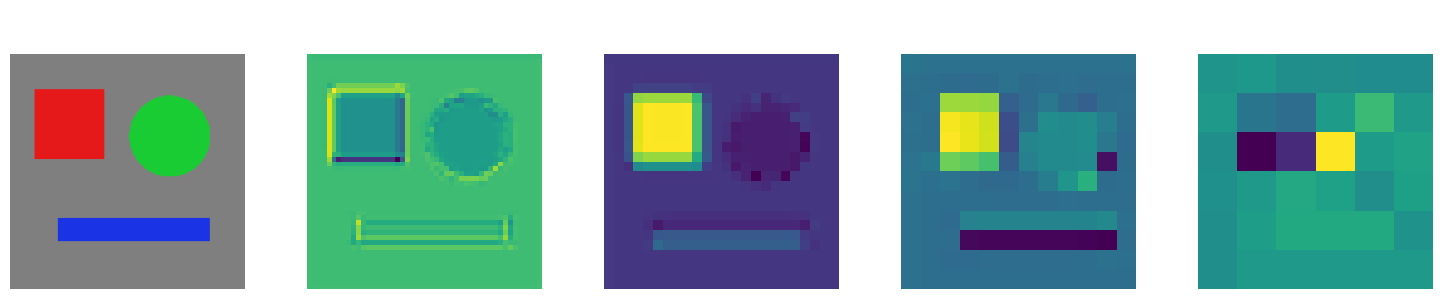

In [23]:
import matplotlib.pyplot as plt

def synthetic_image(size: int) -> torch.Tensor:
    """(1, 3, size, size) image with a red square, a green disc and a blue bar on grey."""
    yy, xx = torch.meshgrid(torch.linspace(0, 1, size), torch.linspace(0, 1, size), indexing="ij")
    img = torch.full((3, size, size), 0.5)
    sq = (xx > 0.1) & (xx < 0.4) & (yy > 0.15) & (yy < 0.45)
    disc = (xx - 0.68) ** 2 + (yy - 0.35) ** 2 < 0.03
    bar = (xx > 0.2) & (xx < 0.85) & (yy > 0.7) & (yy < 0.8)
    for mask, rgb in ((sq, (0.9, 0.1, 0.1)), (disc, (0.1, 0.8, 0.2)), (bar, (0.1, 0.2, 0.9))):
        for c in range(3):
            img[c][mask] = rgb[c]
    mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
    std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
    return ((img - mean) / std)[None], img

name = next(iter(models))
inp, raw = synthetic_image(IMG)
with torch.no_grad():
    maps = models[name](inp).feature_maps
fig, axes = plt.subplots(1, len(maps) + 1, figsize=(3 * (len(maps) + 1), 3), facecolor="white")
axes[0].imshow(raw.permute(1, 2, 0)); axes[0].set_title("input", fontsize=9)
for ax, fm in zip(axes[1:], maps):
    ax.imshow(fm[0].mean(0), cmap="viridis")
    ax.set_title(f"{tuple(fm.shape[1:])} /{IMG // fm.shape[-1]}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.suptitle(f"{name}: channel-mean of every feature map", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

## 9. Experiments from the original walkthrough

The original notebook's hands-on cells, now running on the implementation defined in §4 (they used to import
`hale_core` through a relative `sys.path`, which only worked inside the HaleBlocks repo).

In [24]:
import sys
import numpy as np
import matplotlib.pyplot as plt

In [25]:
"""WSConv2d and NFBlock code walkthrough."""
import sys

import torch
import torch.nn as nn
import math

# ── Key mechanism: Scaled Weight Standardisation ──────────────────────────────
class WSConv2dDemo(nn.Conv2d):
    """Minimal demo of Scaled Weight Standardisation."""
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.gain = nn.Parameter(torch.ones(self.out_channels, 1, 1, 1))

    def forward(self, x):
        w = self.weight
        # Subtract per-filter mean
        w = w - w.mean(dim=[1, 2, 3], keepdim=True)
        # Normalise variance
        w = w / (w.var(dim=[1, 2, 3], keepdim=True, unbiased=False) + 1e-5).sqrt()
        # Scale to maintain unit-variance output
        fan_in = w[0].numel()
        w = w * (self.gain / math.sqrt(fan_in))
        import torch.nn.functional as F
        return F.conv2d(x, w, self.bias, self.stride, self.padding, self.dilation, self.groups)

# Verify: output should have variance ≈ 1 for unit-variance input
conv = WSConv2dDemo(3, 64, 3, padding=1)
x = torch.randn(8, 3, 32, 32)  # unit-variance input
y = conv(x)
print(f'Input  variance: {x.var():.4f}  (target 1.0)')
print(f'Output variance: {y.var():.4f}  (should be ≈ 1.0)')

# ── Demonstrate variance preservation ────────────────────────────────────────
print('\nVariance accumulation comparison:')
print('Block  Standard  NFNet-corrected')
var_std   = 1.0
var_nfnet = 1.0
alpha = 0.2
for k in range(1, 13):
    var_std   += 0.04            # alpha^2 = 0.04 per block
    var_nfnet += 0.0             # NFNet keeps variance constant
    print(f'  {k:2d}     {var_std:.3f}     {var_nfnet:.3f}')

Input  variance: 0.9914  (target 1.0)
Output variance: 0.9626  (should be ≈ 1.0)

Variance accumulation comparison:
Block  Standard  NFNet-corrected
   1     1.040     1.000
   2     1.080     1.000
   3     1.120     1.000
   4     1.160     1.000
   5     1.200     1.000
   6     1.240     1.000
   7     1.280     1.000
   8     1.320     1.000
   9     1.360     1.000
  10     1.400     1.000
  11     1.440     1.000
  12     1.480     1.000


In [26]:
"""NFNet backbone usage example."""
import torch

# List all NFNet variants
nf_backbones = [n for n in list_vision_backbones() if 'nfnet' in n]
print('Registered NFNet variants:', nf_backbones)

# Build NFNet-F0 (smallest)
model = build_vision_backbone('nfnet_f0', img_size=224)
model.eval()

x = torch.randn(2, 3, 224, 224)
out = model(x)

print(f'\nNFNet-F0 outputs:')
print(f'  pooled_output: {out.pooled_output.shape}  (should be [2, 1536])')
print(f'  feature_maps:  {len(out.feature_maps)} scales')
for i, fm in enumerate(out.feature_maps):
    print(f'    stage {i}: {tuple(fm.shape)}')

print(f'\nTotal parameters: {model.num_parameters():,}')
print(f'Trainable params: {model.num_parameters(trainable_only=True):,}')

# Demonstrate AGC (called after loss.backward() in training)
y = out.pooled_output.sum()
y.backward()
print('\nBefore AGC: max grad norm =', max(
    p.grad.norm().item() for p in model.parameters() if p.grad is not None
))
agc_clip(model, lambda_=0.01)
print('After  AGC: max grad norm =', max(
    p.grad.norm().item() for p in model.parameters() if p.grad is not None
))

Registered NFNet variants: ['nfnet_f0', 'nfnet_f1', 'nfnet_f2', 'nfnet_f3', 'nfnet_f4', 'nfnet_f5']



NFNet-F0 outputs:
  pooled_output: torch.Size([2, 1536])  (should be [2, 1536])
  feature_maps:  4 scales
    stage 0: (2, 256, 56, 56)
    stage 1: (2, 512, 28, 28)
    stage 2: (2, 1536, 14, 14)
    stage 3: (2, 1536, 7, 7)

Total parameters: 86,973,228
Trainable params: 86,973,228



Before AGC: max grad norm = 78.38367462158203
After  AGC: max grad norm = 0.3069780766963959


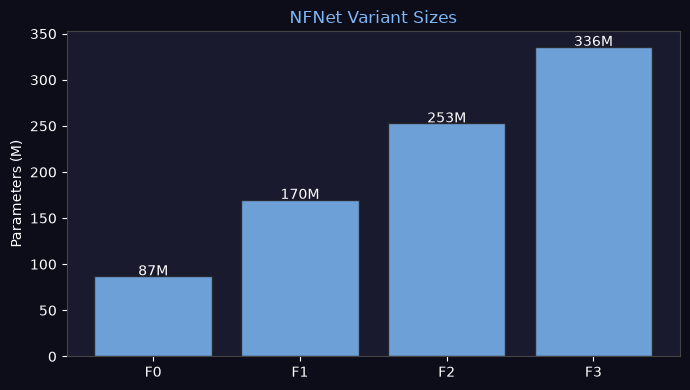

In [27]:
"""Compare NFNet variants: parameters vs depth."""
import matplotlib.pyplot as plt
import torch

plt.style.use('dark_background')
ACCENT = '#7EB8F7'

variants = ['nfnet_f0', 'nfnet_f1', 'nfnet_f2', 'nfnet_f3']
labels   = ['F0', 'F1', 'F2', 'F3']
depths   = [12, 24, 36, 48]  # sum of block counts
params   = []

for name in variants:
    m = build_vision_backbone(name, img_size=224)
    params.append(m.num_parameters() / 1e6)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(labels, params, color=ACCENT, alpha=0.85, edgecolor='#222')
for bar, p in zip(bars, params):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{p:.0f}M', ha='center', color='white', fontsize=10)
ax.set_ylabel('Parameters (M)', color='white')
ax.set_title('NFNet Variant Sizes', color=ACCENT)
ax.tick_params(colors='white')
for spine in ax.spines.values(): spine.set_color('#444')
ax.set_facecolor('#1a1a2e')
fig.patch.set_facecolor('#0d0d1a')
plt.tight_layout()
plt.show()

## References

1. **Brock, A., De, S., Smith, S. L., & Simonyan, K. (2021).**  
   High-Performance Large-Scale Image Recognition Without Normalization.  
   *ICML 2021.* arXiv:2102.06171

2. **Brock, A., De, S., & Smith, S. L. (2021).**  
   Characterizing signal propagation to close the performance gap in unnormalized ResNets.  
   *ICLR 2021.* arXiv:2101.08692

3. **Ioffe, S., & Szegedy, C. (2015).**  
   Batch normalization: Accelerating deep network training by reducing internal covariate shift.  
   *ICML 2015.* arXiv:1502.03167

4. **Huang, G., Sun, Y., Liu, Z., Sedra, D., & Weinberger, K. Q. (2016).**  
   Deep networks with stochastic depth.  
   *ECCV 2016.* arXiv:1603.09382

5. **Hu, J., Shen, L., & Sun, G. (2018).**  
   Squeeze-and-Excitation Networks. *CVPR 2018.* arXiv:1709.01507

6. **Qiao, S., Wang, H., Liu, C., Shen, W., & Yuille, A. (2019).**  
   Weight standardization.  arXiv:1903.10520